# Introduction to Decision Trees & Gini Impurity

Decision Tree membagi ruang fitur secara rekursif melalui serangkaian keputusan biner. Setiap simpul internal menguji suatu fitur, cabang menyatakan hasil uji, dan simpul daun (leaf node) memberikan prediksi kelas.

- Kriteria Pemisahan (Gini Impurity):
Untuk suatu simpul dengan $C$ kelas, Gini Impurity dihitung dengan rumus:
$$G = 1 - \sum_{i=1}^{C} p_i^2$$

di mana $p_i$ adalah proporsi sampel kelas $i$ pada simpul tersebut. Simpul murni (pure node) memiliki nilai $G = 0$. Algoritma memilih fitur dan batas ambang (threshold) yang memaksimalkan penurunan impurity.

Akurasi Decision Tree : 0.8667
Kedalaman Pohon (Depth): 4
Jumlah Daun (Leaves)   : 5

              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        18
  versicolor       0.71      0.83      0.77        12
   virginica       0.85      0.73      0.79        15

    accuracy                           0.87        45
   macro avg       0.85      0.86      0.85        45
weighted avg       0.87      0.87      0.87        45



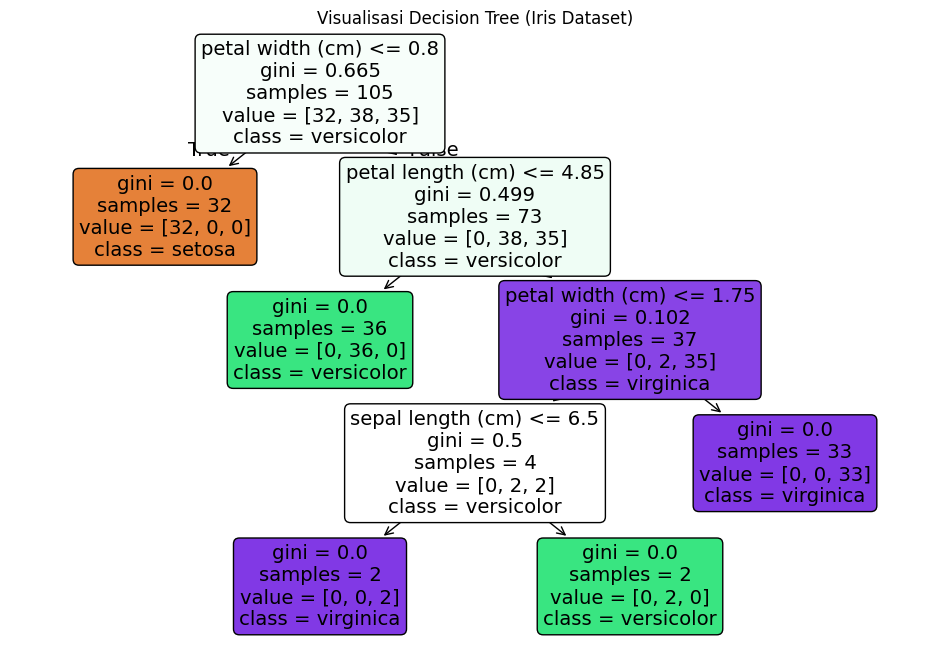

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import (
    RandomForestClassifier,
    GradientBoostingClassifier,
    StackingClassifier
)
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, accuracy_score

warnings.filterwarnings('ignore')

# 1. Memuat Dataset Iris dan Membagi Data (70/30)
iris = load_iris()
X, y = iris.data, iris.target

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=2024
)

# 2. Pelatihan Pohon Keputusan Standar
clf = DecisionTreeClassifier(random_state=2024)
clf.fit(X_train, y_train)

y_pred_dt = clf.predict(X_test)
acc_dt = accuracy_score(y_test, y_pred_dt)

print(f"Akurasi Decision Tree : {acc_dt:.4f}")
print(f"Kedalaman Pohon (Depth): {clf.get_depth()}")
print(f"Jumlah Daun (Leaves)   : {clf.get_n_leaves()}\n")
print(classification_report(y_test, y_pred_dt, target_names=iris.target_names))

# 3. Visualisasi Struktur Decision Tree
plt.figure(figsize=(12, 8))
plot_tree(
    clf,
    feature_names=iris.feature_names,
    class_names=iris.target_names,
    filled=True,
    rounded=True
)
plt.title("Visualisasi Decision Tree (Iris Dataset)")
plt.show()

- Performa Pohon: Pohon menghasilkan akurasi $86.67\%$ pada data uji dengan kedalaman 4 dan 5 simpul daun.

- Analisis Kesalahan: Spesies Setosa terpisah sempurna ($100\%$ precision/recall) pada pemisahan pertama (petal width <= 0.8 cm). Seluruh kesalahan ($6$ sampel) terjadi pada perbatasan spesies Versicolor dan Virginica yang saling tumpang-tindih (overlap).

# Random Forests and Bagging (Variance Reduction)

Random Forest mengatasi kelemahan varians tinggi pada satu pohon keputusan tunggal melalui strategi Bootstrap Aggregating (Bagging):
1. Bootstrap Sampling: Mengambil $M$ sampel acak dengan pengembalian dari data latih.

2. Acak Fitur: Pada setiap pemisahan simpul, hanya mempertimbangkan $\sqrt{p}$ fitur secara acak.

3. Agregasi: Menggabungkan hasil prediksi seluruh pohon melalui pemungutan suara terbanyak (majority voting).

Pengacakan fitur menurunkan korelasi antar pohon ($\rho$), sehingga memperkecil varians total ensemble:
$$\text{Var}(\bar{X}) = \rho \sigma^2 + \frac{1-\rho}{M}\sigma^2$$

Akurasi Random Forest : 0.9111

              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        18
  versicolor       0.83      0.83      0.83        12
   virginica       0.87      0.87      0.87        15

    accuracy                           0.91        45
   macro avg       0.90      0.90      0.90        45
weighted avg       0.91      0.91      0.91        45



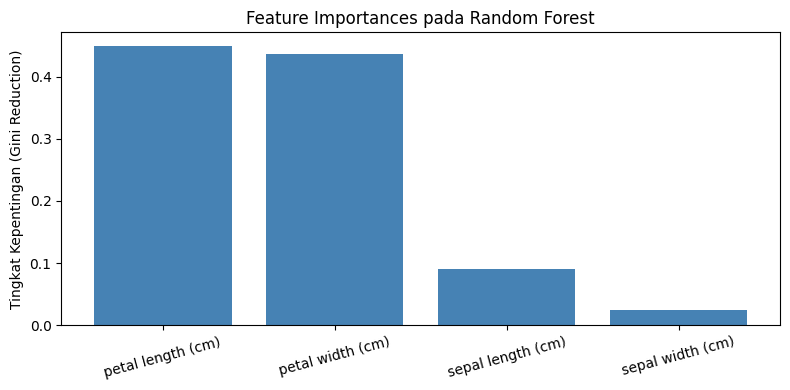

In [ ]:
# 1. Pelatihan Random Forest (100 Pohon)
rf_clf = RandomForestClassifier(n_estimators=100, random_state=2024)
rf_clf.fit(X_train, y_train)

y_pred_rf = rf_clf.predict(X_test)
acc_rf = accuracy_score(y_test, y_pred_rf)

print(f"Akurasi Random Forest : {acc_rf:.4f}\n")
print(classification_report(y_test, y_pred_rf, target_names=iris.target_names))

# 2. Analisis Kepentingan Fitur (Feature Importance)
importances = rf_clf.feature_importances_
indices = np.argsort(importances)[::-1]

plt.figure(figsize=(8, 4))
plt.bar(range(X.shape[1]), importances[indices], color='steelblue')
plt.xticks(range(X.shape[1]), [iris.feature_names[i] for i in indices], rotation=15)
plt.ylabel("Tingkat Kepentingan (Gini Reduction)")
plt.title("Feature Importances pada Random Forest")
plt.tight_layout()
plt.show()

- Peningkatan Akurasi: Akurasi meningkat menjadi $91.11\%$ (menyelamatkan 2 sampel tambahan dibanding pohon tunggal).

- Feature Importance: Petal length ($44.89\%$) dan petal width ($43.60\%$) menyumbang total $88.5\%$ dari seluruh kontribusi pemisahan, sedangkan fitur sepal hanya berkontribusi marjinal

# Gradient Boosting Machines (Bias Reduction)

Berbeda dengan Bagging yang melatih pohon secara paralel, Gradient Boosting melatih pohon secara sekuensial. Setiap pohon baru memprediksi sisa kesalahan (residual / negative gradient) dari kombinasi pohon sebelumnya untuk meminimalkan loss function:

$$F_m(x) = F_{m-1}(x) + \eta \cdot h_m(x)$$

di mana $\eta$ adalah learning rate dan $h_m(x)$ adalah pohon baru.

In [ ]:
# Pelatihan GBM (Default 1000 estimators, learning_rate 0.2)
gbm_clf = GradientBoostingClassifier(
    n_estimators=1000,
    learning_rate=0.2,
    random_state=2024
)
gbm_clf.fit(X_train, y_train)

y_pred_gbm = gbm_clf.predict(X_test)
acc_gbm = accuracy_score(y_test, y_pred_gbm)

print(f"Akurasi GBM (Default/Untuned) : {acc_gbm:.4f}")

Akurasi GBM (Default/Untuned) : 0.8667


- Overfitting pada Untuned GBM: Model menghasilkan akurasi $86.67\%$, setara dengan pohon tunggal. Jumlah $1000$ pohon dengan learning_rate=0.2 terlalu kompleks untuk data berukuran kecil ($105$ sampel latih), sehingga model menghafal noise pada data latih.

# Hyperparameter Tuning untuk Trees & Ensembles

Tuning hiperparameter dilakukan menggunakan GridSearchCV dengan $5$-fold cross-validation untuk menemukan keseimbangan kompleksitas model (learning rate, tree depth, n_estimators).

In [ ]:
# 1. Definisi Parameter Grid
param_grid = {
    'n_estimators': [50, 100, 150],
    'max_depth': [3, 4, 5],
    'learning_rate': [0.01, 0.1, 0.2]
}

# 2. Eksekusi Grid SearchCV
grid_search = GridSearchCV(
    GradientBoostingClassifier(random_state=2024),
    param_grid,
    cv=5,
    scoring='accuracy'
)
grid_search.fit(X_train, y_train)

print(f"Parameter Terbaik : {grid_search.best_params_}")
print(f"Skor CV Terbaik   : {grid_search.best_score_:.4f}")

# 3. Evaluasi Model Hasil Tuning
best_gbm = grid_search.best_estimator_
y_pred_best = best_gbm.predict(X_test)
print(f"Akurasi Data Uji (Tuned GBM) : {accuracy_score(y_test, y_pred_best):.4f}")

Parameter Terbaik : {'learning_rate': 0.01, 'max_depth': 4, 'n_estimators': 50}
Skor CV Terbaik   : 0.9810
Akurasi Data Uji (Tuned GBM) : 0.8667


- Kombinasi Optimal: Konfigurasi terbaik ditemukan pada learning_rate=0.01, max_depth=4, dan n_estimators=50 dengan skor Cross-Validation sebesar $98.10\%$.

- Prinsip Regulasi: Menurunkan learning rate secara signifikan ($\eta=0.01$) dan membatasi jumlah estimasi ($50$ pohon) mencegah model melakukan overfitting pada sampel data kecil.

# Comparing Ensemble Methods (Bagging vs. Boosting vs. Stacking)

Metode Stacking menggabungkan prediksi dari beberapa model dasar (base models) yang beragam dengan menggunakan model penilai (meta-learner, contoh: Logistic Regression) untuk menentukan kombinasi terbaik.

In [ ]:
# 1. Inisialisasi Model Stacking (Random Forest + GBM)
stacking_clf = StackingClassifier(
    estimators=[
        ('rf', RandomForestClassifier(n_estimators=100, random_state=2024)),
        ('gb', GradientBoostingClassifier(n_estimators=100, random_state=2024))
    ],
    final_estimator=LogisticRegression(max_iter=1000),
    cv=5
)

# 2. Fit & Evaluasi Stacking
stacking_clf.fit(X_train, y_train)
y_pred_stacking = stacking_clf.predict(X_test)
acc_stacking = accuracy_score(y_test, y_pred_stacking)

# 3. Ringkasan Perbandingan Akhir
summary_df = pd.DataFrame({
    'Metode Ensemble': ['Decision Tree (Single)', 'Random Forest (Bagging)', 'Gradient Boosting (Boosting)', 'Stacking (Meta-Learner)'],
    'Akurasi Data Uji': [acc_dt, acc_rf, acc_gbm, acc_stacking]
})

print("\n--- Tabel Perbandingan Performa Chapter 8 ---")
print(summary_df.to_string(index=False))


--- Tabel Perbandingan Performa Chapter 8 ---
             Metode Ensemble  Akurasi Data Uji
      Decision Tree (Single)          0.866667
     Random Forest (Bagging)          0.911111
Gradient Boosting (Boosting)          0.866667
     Stacking (Meta-Learner)          0.866667


- Hasil Akhir: Random Forest unggul ($91.11\%$) dibanding Boosting dan Stacking ($86.67\%$)

- Kesimpulan Praktis: Pada dataset berukuran kecil dan bersih dengan masalah utama berupa varians (Iris Dataset), pendekatan Bagging (Random Forest) memberikan hasil paling stabil dan efisien tanpa risiko overfitting berlebih.